# Duplicate detection: the pairs and what the evaluation finds

This notebook describes the frozen pairs in `data/pairs.jsonl` and replays them through `graph.py`'s duplicate check
with `evaluate.py` (see `SPEC.md`). Run it from the repository by hand after any change to the pairs or to `graph.py`:
it needs pandas and matplotlib, which the project does not install, and CI does not run it.

**The question.** `graph.py add` checks a new name against an entity already in the graph and gives one of three
outcomes: *refuse* (same id, or the same name unless the ids conflict), *ask* (a similar name or a name equal to an alias), or *add*. Each pair
is an existing entity and a new name, known to be the same thing or different things. The check is right when it
finds a duplicate and wrong in three ways:

| Pair is | refuse | ask | add |
|---|---|---|---|
| the same thing | right | right | **missed duplicate** |
| different things | **wrong merge** | **needless ask** | right |

Rates are never averaged across kinds: the kinds are filled to targets, not in the proportions of real use.

## Glossary

| Kind | Pair | Label |
|---|---|---|
| similar name | an entity's first name, then another of its names that shares a word with it or is close in spelling | same |
| known alias | the first name with its other names as aliases, then one of them | same |
| messy | a name, then the same name as text extracted from a PDF would show it (twelve kinds of change) | same |
| dissimilar name | an entity's first name, then a name that shares no word and is far in spelling (`data build tool`, `dbt`) | same |
| look-alike | a seed, then a different entity found by rules (same surname and initial, a shared word, the same family) | different |
| same name | two different entities with exactly the same name (two people called `Jing Chen`) | different |
| alias collision | an entity with aliases, then a different entity named like one of them | different |

In [1]:
import importlib.util
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    (
        folder
        for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (folder / "skills" / "graph").exists()
    ),
    None,
)
if ROOT is None:
    raise SystemExit("run this notebook from inside the repository")


def load(name, path):
    # The module at path, loaded fresh under name. A module of that name already in this kernel (an older copy, or an
    # installed package such as Hugging Face's `evaluate`) is replaced, so the notebook runs this repository's code.
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


graph = load("graph", ROOT / "skills" / "graph" / "scripts" / "graph.py")
ev = load("evaluate", ROOT / "evals" / "dedup" / "evaluate.py")

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#7a5cc8"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})

pairs = ev.load_pairs(ev.PAIRS)
frame = pd.DataFrame(
    {
        "kind": [ev.kind_of(p) for p in pairs],
        "group": [p["kind"] for p in pairs],
        "label": [p["label"] for p in pairs],
        "type": [p["type"] for p in pairs],
        "split": [p["split"] for p in pairs],
        "source": [p["source"] for p in pairs],
    }
)
manifest = json.loads((ev.HERE / "data" / "manifest.json").read_text(encoding="utf-8"))
print(len(pairs), "pairs; built", manifest["built"], "from a snapshot of", len(manifest["sources snapshot"]), "files")

3818 pairs; built 2026-11-10 from a snapshot of 10 files


## 1. Size and balance

Dev and test are split by entity, so no entity is in both. Each kind has a target per split and is filled with what its
candidates allow: a kind with fewer candidates gives all it has. The kinds that fall short are the ones to read with
care, and the next table shows which.

In [2]:
order = ["similar name", "known alias", "messy", "dissimilar name", "look-alike", "same name", "alias collision"]
sizes = frame.groupby(["group", "split"]).size().unstack(fill_value=0).reindex(order)
sizes["target per split"] = [manifest["parameters"]["targets per split"].get(k, 240) for k in order]
sizes

split,dev,test,target per split
group,,,
similar name,500,500,500
known alias,200,200,200
messy,239,241,240
dissimilar name,300,300,300
look-alike,500,500,500
same name,165,164,300
alias collision,4,5,300


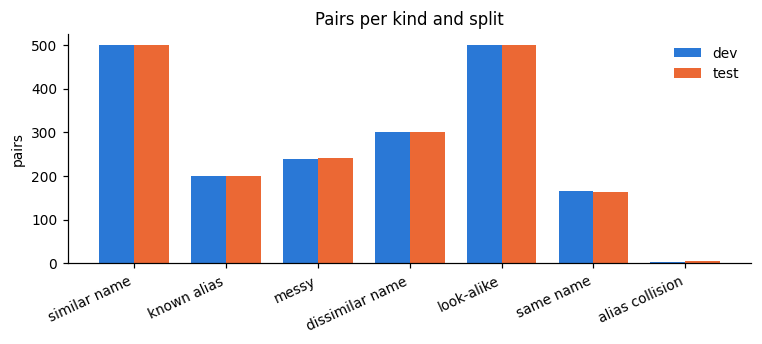

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.38
positions = range(len(order))
ax.bar([p - width / 2 for p in positions], sizes["dev"], width, label="dev", color=SERIES[0])
ax.bar([p + width / 2 for p in positions], sizes["test"], width, label="test", color=SERIES[1])
ax.set_xticks(list(positions))
ax.set_xticklabels(order, rotation=25, ha="right")
ax.set_ylabel("pairs")
ax.set_title("Pairs per kind and split")
ax.legend(frameon=False)
fig.tight_layout()

In [4]:
frame[frame.split == "dev"].groupby(["group", "type"]).size().unstack(fill_value=0).reindex(order)

type,author,dataset,method,model,tool
group,,,,,
similar name,188,189,35,13,75
known alias,45,53,45,15,42
messy,61,53,29,53,43
dissimilar name,21,111,111,3,54
look-alike,114,129,115,116,26
same name,165,0,0,0,0
alias collision,4,0,0,0,0


The thinnest kinds are **alias collision** and **same name**. Curated sources rarely give two different things the
same name, so these pairs come almost only from DBLP authors: outside authors there is one same-name pair and one
alias-collision pair in all. Read their rates with their counts; the intervals below are wide on purpose.

## 2. What the pairs look like

One real pair of each kind, drawn at random with a fixed seed. The names are as they are in the sources.

In [5]:
import random

rng = random.Random(7)
rows = []
for kind in order:
    pool = [p for p in pairs if p["kind"] == kind and p["split"] == "dev"]
    p = rng.choice(pool)
    rows.append(
        {
            "kind": ev.kind_of(p),
            "type": p["type"],
            "existing": p["existing"]["name"],
            "aliases": "; ".join(p["existing"]["aliases"]),
            "new name": p["new"]["name"],
            "label": p["label"],
        }
    )
pd.DataFrame(rows)

,kind,type,existing,aliases,new name,label
0,similar name,author,Enrique S. Quintana-Ortí,,Enrique S. Quintana,same
1,known alias,author,A. P. Thakoor,Anilkumar P. Thakoor,Anilkumar P. Thakoor,same
2,messy: invisible,author,Mamoru Nakajima,,Mamoru Naka​jima,same
3,dissimilar name,dataset,AIH,,Amodal InterHand,same
4,look-alike,author,ShiJi Song,,Shaozhen Song,different
5,same name,author,Hua Wu,,Hua Wu,different
6,alias collision,author,Christian Rosenke,Christian Hundt,Christian Hundt,different


## 3. Where the labels come from

*Same thing* is the sources' own grouping of names. DBLP's variants are curated by its editors. For every other source,
Jev (a decision model) judged each second name at build time, and a name is dropped when Jev puts at most `MAX_SAME` of
its probability on "same thing". The table counts Jev's answers by the probability it gave. One answer was removed from
`data/audit.jsonl` after the build because the second name was an email address, so the file holds one answer and one
removed name fewer than `manifest.json` counts.

The 200-pair hand check (`hand_check.py`) is filled in, and the second cell below scores it. The spec accepts a
`MAX_SAME` only if the names it removes were the same thing at most 10% of the time by hand.

answers: 3381 | spent: $0.0670
removed (P(same thing) <= 0.2): 250


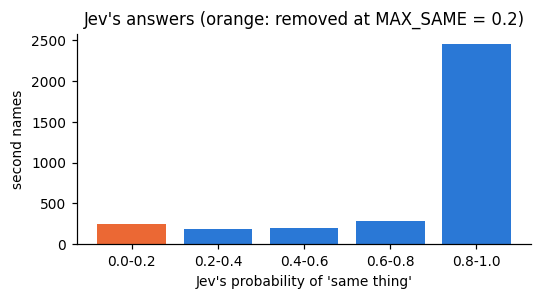

In [6]:
answers = [
    json.loads(line)
    for line in (ev.HERE / "data" / "audit.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
same = pd.Series([a["probabilities"].get("same_thing", 0.0) for a in answers])
bands = pd.cut(
    same, [0, 0.2, 0.4, 0.6, 0.8, 1.0001], right=False, labels=["0.0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0"]
)
counts = bands.value_counts().sort_index()
spent = sum(a.get("cost") or 0 for a in answers)
print(f"answers: {len(answers)} | spent: ${spent:.4f}")
print(f"removed (P(same thing) <= 0.2): {int((same <= 0.2).sum())}")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(counts.index.astype(str), counts.values, color=[SERIES[1]] + [SERIES[0]] * 4)
ax.set_xlabel("Jev's probability of 'same thing'")
ax.set_ylabel("second names")
ax.set_title("Jev's answers (orange: removed at MAX_SAME = 0.2)")
fig.tight_layout()

In [7]:
hc = load("hand_check", ROOT / "evals" / "dedup" / "hand_check.py")
if hc.KEY.exists():
    scored = hc.score(hc.SHEET, hc.KEY)
    bands = scored["same thing by hand, by band of Jev's P(same thing)"]
    print(f"judged: {scored['judged']} | unsure: {scored['unsure']} | decided by: {scored['decided by']}")
    print("same thing by hand, by band:", {band: f"{v['bad']}/{v['total']}" for band, v in bands.items()})
    errors = scored["label disagrees with the person, by kind"]
    print("label disagrees with the person:", {kind: f"{v['bad']}/{v['total']}" for kind, v in errors.items()})
    print(f"suggested MAX_SAME: {scored['suggested MAX_SAME']} (now {scored['MAX_SAME now']})")
else:
    print(f"no key at {hc.KEY} (hand_check.py make writes it), so the sheet cannot be scored here")

judged: 200 | unsure: 6 | decided by: {'person': 200, 'person, overriding Claude': 0, 'Claude only': 0}
same thing by hand, by band: {'0.0-0.2': '3/19', '0.2-0.4': '4/20', '0.4-0.6': '9/19', '0.6-0.8': '13/18', '0.8-1.0': '20/20'}
label disagrees with the person: {'dissimilar name': '1/25', 'known alias': '1/25', 'look-alike': '0/23', 'similar name': '3/25'}
suggested MAX_SAME: None (now 0.2)


At `MAX_SAME = 0.2`, 3 of the 19 removed names in the sheet were the same thing by hand: 16%, above the 10% the spec
allows, and no lower band does better, so the scorer suggests no threshold. The labels in the pairs are unchanged until
the pairs are rebuilt. Two limits of the check itself: every one of the 200 verdicts is an `ok` to a verdict Claude
filled in first, none overriding it, so it measures agreement with Claude's reading rather than an independent one; and
the key that scores the sheet lives in `.cache/`, which git ignores, so only the checkout that made the sheet can score it.

## 4. What `graph.py add` does with the pairs

Each pair is replayed twice: with the entities' real ids (**ids**) and with names only. The bars show the share of
each kind that ends in each outcome at the default settings. The *right* outcome depends on the label: for a
same-thing pair, refuse or ask is right and add is a miss; for a different-thing pair, add is right and refuse is a
wrong merge. Dev split.

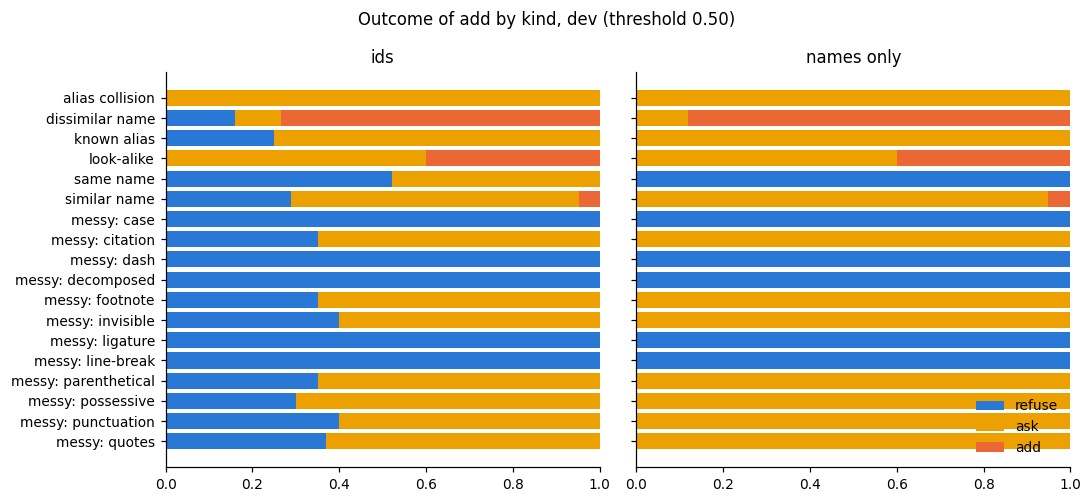

In [8]:
dev = [p for p in pairs if p["split"] == "dev"]
setting = (graph.SIMILARITY, "ask")
results = ev.replay(dev, [setting])
share = {}
for run in ev.RUNS:
    table = pd.DataFrame({"kind": [ev.kind_of(p) for p in dev], "outcome": results[run][setting]})
    share[run] = pd.crosstab(table["kind"], table["outcome"], normalize="index").reindex(
        columns=["refuse", "ask", "add"], fill_value=0
    )

kinds = sorted(share["names only"].index, key=lambda k: (k.split(":")[0] != k, k))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
colours = {"refuse": SERIES[0], "ask": SERIES[3], "add": SERIES[1]}
for ax, run in zip(axes, ev.RUNS):
    left = pd.Series(0.0, index=kinds)
    for outcome in ("refuse", "ask", "add"):
        values = share[run].reindex(kinds)[outcome]
        ax.barh(kinds, values, left=left, label=outcome, color=colours[outcome])
        left += values
    ax.set_title(run)
    ax.set_xlim(0, 1)
axes[0].invert_yaxis()
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle(f"Outcome of add by kind, dev (threshold {graph.SIMILARITY:.2f})")
fig.tight_layout()

## 5. The rates, with their counts

Each rate is a count over the pairs it can happen to, with a 95% Wilson interval. A dash means the rate does not apply to
that kind (a same-thing pair cannot be a wrong merge).

In [9]:
text, data = ev.build_report(dev, [setting], "dev")
rate_rows = []
for run in ev.RUNS:
    for kind, found in data["settings"][f"{run}, {ev.setting_name(setting)}"].items():
        for rate, (bad, total) in found.items():
            if total:
                low, high = ev.wilson(bad, total)
                rate_rows.append(
                    {
                        "run": run,
                        "kind": kind,
                        "rate": rate,
                        "bad": bad,
                        "of": total,
                        "share": bad / total,
                        "low": low,
                        "high": high,
                    }
                )
rates = pd.DataFrame(rate_rows)
rates[rates.run == "names only"].drop(columns="run").round(3).reset_index(drop=True)

,kind,rate,bad,of,share,low,high
0,alias collision,wrong merges,0,4,0.000,0.000,0.490
1,alias collision,needless asks,4,4,1.000,0.510,1.000
2,dissimilar name,missed duplicates,264,300,0.880,0.838,0.912
3,known alias,missed duplicates,0,200,0.000,0.000,0.019
4,look-alike,wrong merges,0,500,0.000,0.000,0.008
5,look-alike,needless asks,300,500,0.600,0.556,0.642
6,messy: case,missed duplicates,0,20,0.000,0.000,0.161
7,messy: citation,missed duplicates,0,20,0.000,0.000,0.161
8,messy: dash,missed duplicates,0,20,0.000,0.000,0.161
9,messy: decomposed,missed duplicates,0,20,0.000,0.000,0.161


What to read from it:

- **Known alias, messy and similar name** are the pairs a search by spelling should find. Their missed rates are the
  honest measure of the detector on spelling. The messy kinds are near zero for two reasons. Five of them (case, dash, decomposed, ligature, line-break) still match by name, because `name_key` folds case and ligatures and drops separators, so they are refused. The other seven (citation, footnote, invisible, parenthetical, possessive, punctuation, quotes) are caught by the similarity score, so they are asks and depend on `SIMILARITY`.
- **Dissimilar name** is reported apart and never mixed into another figure. A search by spelling cannot find
  `data build tool` for `dbt`, and the large miss rate is the size of the scope we chose not to chase.
- **Look-alike** shows the price of the 0.5 threshold: needless asks. The threshold sweep below shows what moving it buys.
- **Same name** is a wrong merge with names only for every pair, by construction: nothing in a name tells two
  `Jing Chen`s apart. Ids help only where both people have an ORCID.

In [10]:
ids_run = pd.DataFrame(
    {
        "ids run": [results["ids"][setting].count(o) for o in ("refuse", "ask", "add")],
        "names only": [results["names only"][setting].count(o) for o in ("refuse", "ask", "add")],
    },
    index=["refuse", "ask", "add"],
)
same_name = [p for p in dev if p["kind"] == "same name"]
by_run = {run: Counter(o for p, o in zip(dev, results[run][setting]) if p["kind"] == "same name") for run in ev.RUNS}
print(f"same-name pairs ({len(same_name)}): ids run {dict(by_run['ids'])} | names only {dict(by_run['names only'])}")
ids_run

same-name pairs (165): ids run {'refuse': 86, 'ask': 79} | names only {'refuse': 165}


,ids run,names only
refuse,478,265
ask,986,1153
add,444,490


## 6. The threshold

`SIMILARITY` decides only between ask and add: a similarity score never refuses, so it cannot cause a wrong merge. Raising
it trades fewer needless asks (look-alikes) for more missed duplicates (similar names). The sweep scores each pair once and
covers every threshold from 0.30 to 0.90. The rule in the spec picks, on dev, the highest threshold that misses at most 5%
of similar-name pairs, and checks it on test. The sweep's miss rate counts similar-name pairs only: the seven messy kinds that the score catches (section 5) are not in it, so the cell after the sweep says at which threshold they would start to be missed.

Chosen on dev: the highest threshold with at most 5% missed duplicates on similar-name pairs is 0.45.


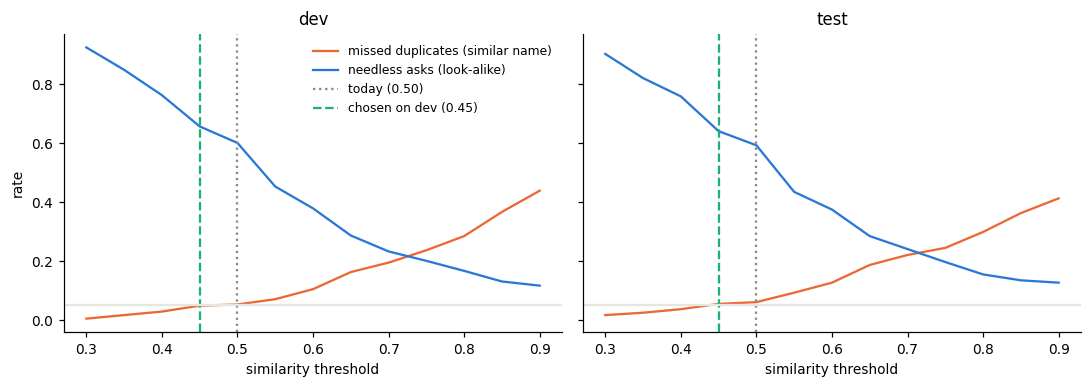

In [11]:
by_split = {s: [p for p in pairs if p["split"] == s] for s in ("dev", "test")}
sweep_text, sweep = ev.sweep_report(by_split, ev.LIMIT)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, split in zip(axes, ("dev", "test")):
    points = sweep["points"][split]
    xs = [pt["threshold"] for pt in points]
    ax.plot(
        xs,
        [pt["missed"][0] / pt["missed"][1] for pt in points],
        color=SERIES[1],
        label="missed duplicates (similar name)",
    )
    ax.plot(
        xs,
        [pt["needless"][0] / pt["needless"][1] for pt in points],
        color=SERIES[0],
        label="needless asks (look-alike)",
    )
    ax.axvline(graph.SIMILARITY, color="#8a8984", linestyle=":", label=f"today ({graph.SIMILARITY:.2f})")
    if sweep["chosen on dev"]:
        ax.axvline(
            sweep["chosen on dev"],
            color=SERIES[2],
            linestyle="--",
            label=f"chosen on dev ({sweep['chosen on dev']:.2f})",
        )
    ax.axhline(ev.LIMIT, color="#e6e5e0")
    ax.set_title(split)
    ax.set_xlabel("similarity threshold")
axes[0].set_ylabel("rate")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
print(sweep_text.splitlines()[-1])

In [12]:
prepared = [(p, ev.prepare(p, False)) for p in dev if p["kind"] == "messy"]
by_score = sorted(((r["score"], ev.kind_of(p)) for p, r in prepared if not r["strong"]), key=lambda item: item[0])
lowest, kind = by_score[0]
print(f"{len(by_score)} of {len(prepared)} messy pairs are caught by the score, not by name.")
print(f"The lowest score is {lowest:.2f} ({kind}): a threshold above it misses messy pairs the sweep does not count.")

139 of 239 messy pairs are caught by the score, not by name.
The lowest score is 0.67 (messy: footnote): a threshold above it misses messy pairs the sweep does not count.


The chosen threshold keeps almost every similar spelling and pays for it in needless asks: the curve has no knee. The
look-alike rate follows the look-alike rules, which are ours, so it compares settings and does not predict real use.

### The threshold by type (exploratory)

The same rule, run on each type alone: the highest threshold that misses at most 5% of that type's similar-name pairs on
dev, and what it gives on dev and on test. The last row is all types together, the choice above.

In [13]:
type_rows = []
type_curves = {}
for entity_type in ("author", "dataset", "method", "model", "tool", None):
    found = {}
    for split in ("dev", "test"):
        subset = [p for p in by_split[split] if entity_type in (None, p["type"])]
        found[split] = ev.curve(subset, [ev.prepare(p, False) for p in subset])
    chosen = ev.choose(found["dev"], ev.LIMIT)
    type_curves[entity_type or "all types"] = (found, chosen)
    row = {
        "type": entity_type or "all types",
        "similar-name pairs, dev/test": f"{found['dev'][0]['missed'][1]}/{found['test'][0]['missed'][1]}",
        "look-alike pairs, dev/test": f"{found['dev'][0]['needless'][1]}/{found['test'][0]['needless'][1]}",
        "chosen on dev": chosen,
    }
    if chosen is not None:
        at = {split: next(pt for pt in found[split] if pt["threshold"] == chosen) for split in found}
        row["missed duplicates, dev"] = ev.cell(*at["dev"]["missed"])
        row["missed duplicates, test"] = ev.cell(*at["test"]["missed"])
        row["needless asks, test"] = ev.cell(*at["test"]["needless"])
    type_rows.append(row)
pd.DataFrame(type_rows)

,type,"similar-name pairs, dev/test","look-alike pairs, dev/test",chosen on dev,"missed duplicates, dev","missed duplicates, test","needless asks, test"
0,author,188/183,114/126,0.65,0.043 (0.022-0.082) 8/188,0.055 (0.030-0.098) 10/183,0.151 (0.099-0.224) 19/126
1,dataset,189/182,129/111,0.40,0.048 (0.025-0.088) 9/189,0.060 (0.034-0.105) 11/182,0.874 (0.799-0.923) 97/111
2,method,35/38,115/95,0.40,0.029 (0.005-0.145) 1/35,0.026 (0.005-0.135) 1/38,0.800 (0.709-0.868) 76/95
3,model,13/12,116/124,0.60,0.000 (0.000-0.228) 0/13,0.083 (0.015-0.354) 1/12,0.411 (0.329-0.499) 51/124
4,tool,75/85,26/44,0.55,0.040 (0.014-0.111) 3/75,0.129 (0.074-0.217) 11/85,0.250 (0.146-0.394) 11/44
5,all types,500/500,500/500,0.45,0.048 (0.032-0.070) 24/500,0.054 (0.037-0.077) 27/500,0.640 (0.597-0.681) 320/500


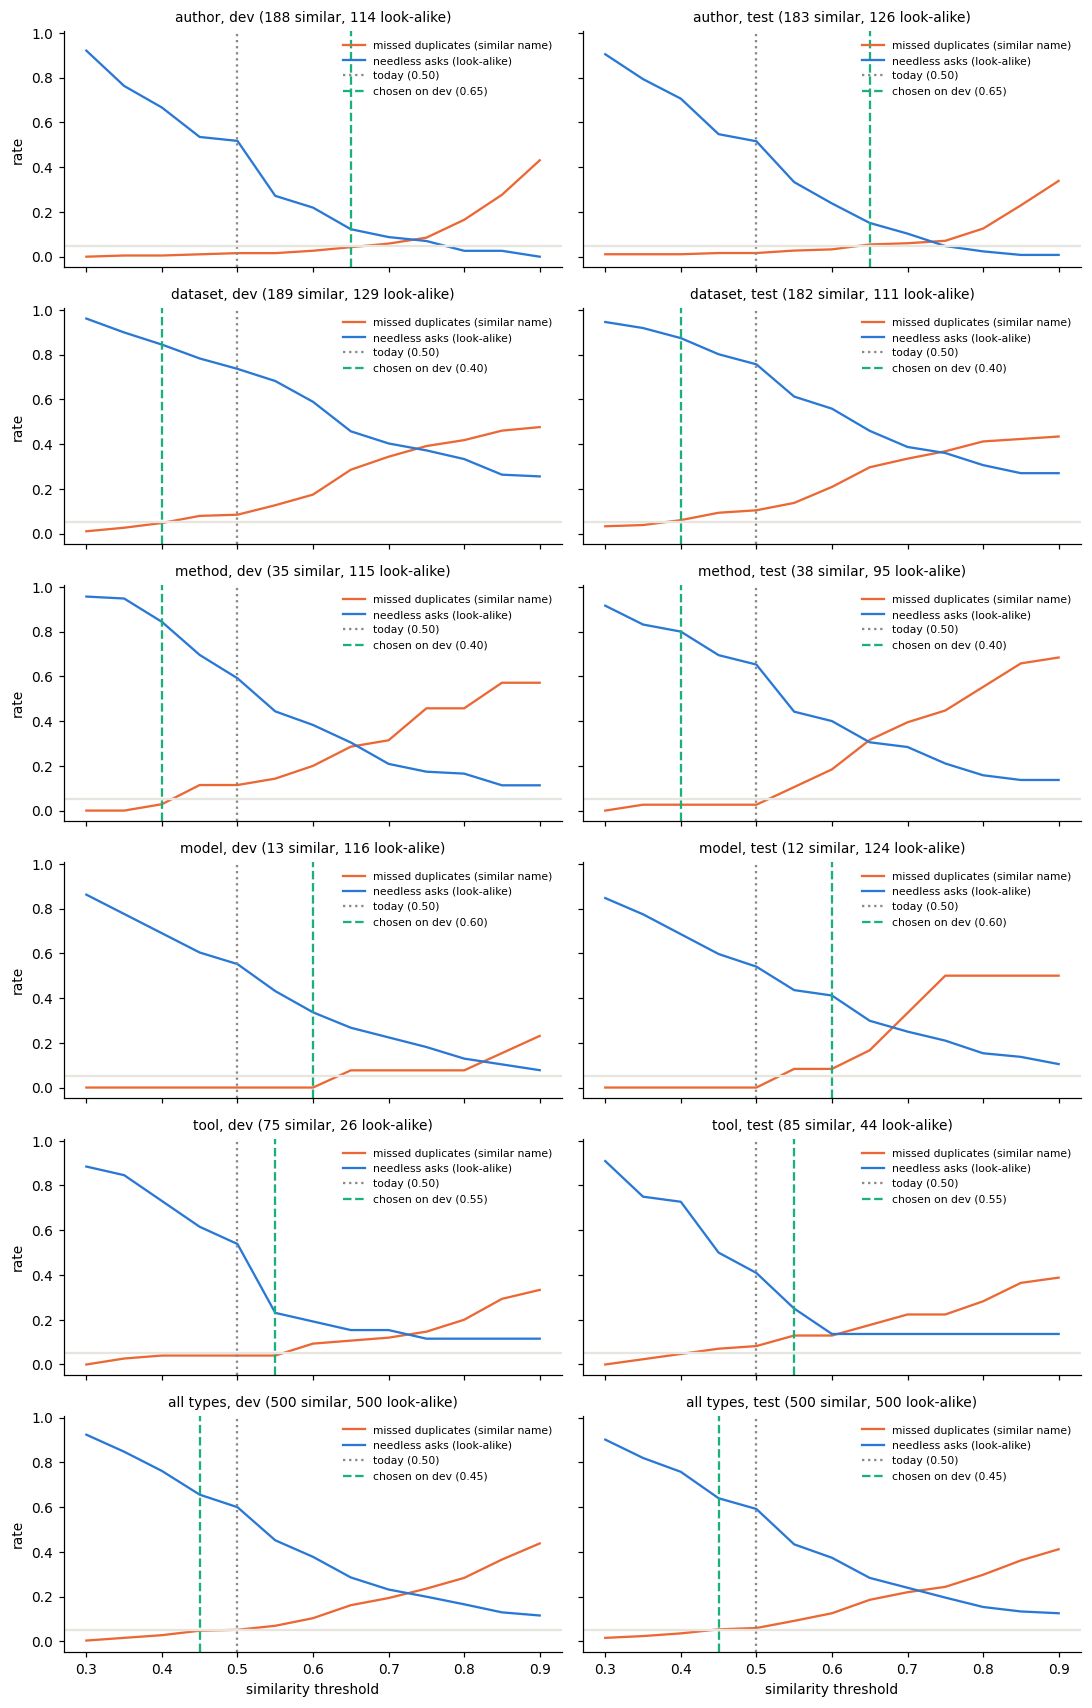

In [14]:
names = list(type_curves)
fig, axes = plt.subplots(len(names), 2, figsize=(10, 2.6 * len(names)), sharex=True, sharey=True)
for row_axes, name in zip(axes, names):
    found, chosen = type_curves[name]
    for ax, split in zip(row_axes, ("dev", "test")):
        points = found[split]
        xs = [pt["threshold"] for pt in points]
        ax.plot(
            xs,
            [pt["missed"][0] / pt["missed"][1] for pt in points],
            color=SERIES[1],
            label="missed duplicates (similar name)",
        )
        ax.plot(
            xs,
            [pt["needless"][0] / pt["needless"][1] for pt in points],
            color=SERIES[0],
            label="needless asks (look-alike)",
        )
        ax.axvline(graph.SIMILARITY, color="#8a8984", linestyle=":", label=f"today ({graph.SIMILARITY:.2f})")
        if chosen is not None:
            ax.axvline(chosen, color=SERIES[2], linestyle="--", label=f"chosen on dev ({chosen:.2f})")
        ax.axhline(ev.LIMIT, color="#e6e5e0")
        ax.set_title(
            f"{name}, {split} ({points[0]['missed'][1]} similar, {points[0]['needless'][1]} look-alike)", fontsize=9
        )
        ax.legend(frameon=False, fontsize=7, loc="upper right")
    row_axes[0].set_ylabel("rate")
for ax in axes[-1]:
    ax.set_xlabel("similarity threshold")
fig.tight_layout()

Read it as a description, not as a recommendation:

- **The types do differ.** Authors tolerate a higher threshold than datasets and methods, so one constant is a compromise.
- **Some types have too few pairs.** Model has about a dozen similar-name pairs per split, so one miss moves its rate by
  eight points, and a limit of 5% is noise there. Where a type's test rate lands well above its dev rate, the choice did
  not hold.
- **The needless-ask side depends on our look-alike rules,** which differ by type (surname and initial for authors, a
  shared word for the others). A per-type optimum partly reflects those rules.
- **`graph.py` has one constant, `SIMILARITY`.** A per-type table would add a rule to the detector. The only gap large
  enough, with 180 or more pairs per split in both types, is authors against the rest.

## 7. The first change to judge: a name equal to an alias

Today a name equal to an existing entity's alias is **asked** about. The change under consideration **refuses** it, like an
equal name, which saves Claude a choice each time the alias is added again. The cost is a wrong merge wherever two
different things share an alias. The list of pairs that change is what the change is judged on.

In [15]:
settings = ev.settings_of([graph.SIMILARITY], ["ask", "refuse"])
both = ev.replay(by_split["test"], settings)
rows = []
for run in ev.RUNS:
    for pair, before, after in ev.changed(by_split["test"], both[run][settings[0]], both[run][settings[1]]):
        rows.append({"run": run, "kind": ev.kind_of(pair), "label": pair["label"], "from": before, "to": after})
changes = pd.DataFrame(rows)
changes.groupby(["run", "kind", "label", "from", "to"]).size().rename("pairs").reset_index()

,run,kind,label,from,to,pairs
0,ids,alias collision,different,ask,refuse,2
1,ids,known alias,same,ask,refuse,142
2,names only,alias collision,different,ask,refuse,5
3,names only,known alias,same,ask,refuse,200


Read it by label: every *same-thing* pair that moves from ask to refuse is an ask saved (both are right). Every
*different-thing* pair that moves is a wrong merge added. The test split holds only a handful of alias-collision pairs
(see section 1), so the cost side of this trade is measured on very few pairs. That is a limit of the sources, and
it means a decision on this change should wait for more collisions or for logged use.

## 8. Limits

- The hand check (section 3) says that `MAX_SAME = 0.2` removes names that were the same thing 16% of the time, above
  the 10% the spec allows, and suggests no threshold. The pairs keep the labels that 0.2 gave them.
- Alias-collision and same-name pairs are few outside authors (section 1); models have only a dozen similar-name pairs
  per split and few dissimilar ones.
- One existing entity per pair: the evaluation cannot show asks growing as a graph fills up with look-alikes.
- Look-alike rates depend on the look-alike rules. They compare settings; they do not predict real use.
- Claude's decisions after an ask or a refusal are not measured: a needless ask costs a decision, and a refusal that is
  wrong sends Claude toward `update` on the wrong entity.
- The pairs are frozen, and the sources change: a rebuild without the cache gives other pairs.